<a href="https://colab.research.google.com/github/greidias-ctrl/Cienciadedados/blob/main/TRABALHO_Untitled4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Carregamento do CSV

In [17]:
from google.colab import files

arquivo = files.upload()

nome_arquivo = list(arquivo.keys())[0]
df = pd.read_csv(nome_arquivo)

display(df.head())

Saving dataset_jornalismo_esportivo_segunda_chamada.csv to dataset_jornalismo_esportivo_segunda_chamada (1).csv


,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
0,2026-10-01,Site,Clássico nacional movimenta a rodada,Futebol,Notícia,Manhã,52000,43000,78.0,1200,180,310,4100,145,4300
1,2026-10-01,Site,Como o basquete mudou sua defesa,Basquete,Análise,Tarde,28000,22500,150.0,720,140,260,2300,92,2500
2,2026-10-01,YouTube,Capitã fala sobre preparação para a final,Vôlei,Entrevista,Noite,18000,14500,275.0,980,195,410,1900,105,2300
3,2026-10-01,Site,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Tarde,24000,19500,220.0,650,120,300,2500,120,3800
4,2026-10-05,YouTube,Os melhores lances do fim de semana,Futebol,Vídeo,Noite,68000,55000,210.0,2600,350,620,5300,190,5200


1 - Diagnóstico dos dados


In [9]:
print(df.shape)
df.info()
print(df.isna().sum())
print(df.duplicated().sum())

(24, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   data_publicacao       24 non-null     object 
 1   portal                24 non-null     object 
 2   titulo                24 non-null     object 
 3   modalidade            24 non-null     object 
 4   tipo_conteudo         24 non-null     object 
 5   turno_publicacao      24 non-null     object 
 6   visualizacoes         24 non-null     int64  
 7   usuarios_unicos       24 non-null     int64  
 8   tempo_medio_segundos  23 non-null     float64
 9   curtidas              24 non-null     int64  
 10  comentarios           24 non-null     int64  
 11  compartilhamentos     24 non-null     int64  
 12  cliques_relacionados  24 non-null     int64  
 13  novos_assinantes      24 non-null     int64  
 14  receita_publicitaria  24 non-null     int64  
dtypes: float64(1), i

Tratamento dos dados

In [13]:
dados = df.copy()

dados["modalidade"] = dados["modalidade"].str.strip()
dados["data_publicacao"] = pd.to_datetime(
    dados["data_publicacao"], errors="coerce"
)

print("Valor ausente que será preservado:")
display(dados[dados["tempo_medio_segundos"].isna()])

print("Modalidades após a correção:")
print(dados["modalidade"].unique())

Valor ausente que será preservado:


,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
19,2026-10-17,YouTube,Piloto comenta disputa pelo pódio,Automobilismo,Entrevista,Noite,23000,18500,NaN,820,145,350,2600,130,3900


Modalidades após a correção:
['Futebol' 'Basquete' 'Vôlei' 'Automobilismo']


2 - Criar as cinco métricas

In [14]:
dados["total_interacoes"] = (
    dados["curtidas"] + dados["comentarios"] + dados["compartilhamentos"]
)

dados["taxa_engajamento_pct"] = (
    dados["total_interacoes"] /
    dados["visualizacoes"].replace(0, np.nan)
) * 100

dados["taxa_recirculacao_pct"] = (
    dados["cliques_relacionados"] /
    dados["visualizacoes"].replace(0, np.nan)
) * 100

dados["taxa_conversao_pct"] = (
    dados["novos_assinantes"] /
    dados["cliques_relacionados"].replace(0, np.nan)
) * 100

dados["rpm"] = (
    dados["receita_publicitaria"] /
    dados["visualizacoes"].replace(0, np.nan)
) * 1000

dados["frequencia_media"] = (
    dados["visualizacoes"] /
    dados["usuarios_unicos"].replace(0, np.nan)
)

display(dados[[
    "titulo", "taxa_engajamento_pct", "taxa_recirculacao_pct",
    "taxa_conversao_pct", "rpm", "frequencia_media"
]].round(2))

,titulo,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
0,Clássico nacional movimenta a rodada,3.25,7.88,3.54,82.69,1.21
1,Como o basquete mudou sua defesa,4.00,8.21,4.00,89.29,1.24
2,Capitã fala sobre preparação para a final,8.81,10.56,5.53,127.78,1.24
3,Bastidores da equipe antes do grande prêmio,4.46,10.42,4.80,158.33,1.23
4,Os melhores lances do fim de semana,5.25,7.79,3.58,76.47,1.24
5,Time confirma reforço para a temporada,3.73,6.77,3.33,70.97,1.22
6,O saque que decidiu as últimas partidas,7.84,10.62,5.29,125.00,1.25
7,Volta rápida comentada por especialista,5.03,10.34,4.83,151.72,1.23
8,Pressão alta explica vitória no clássico,3.74,9.07,4.49,95.35,1.23
9,Armador revela rotina de treinamento,6.23,9.23,4.79,119.23,1.24


In [18]:
primeiro = dados.iloc[0]

print("Título:", primeiro["titulo"])
print("Engajamento: {:.2f}%".format(primeiro["taxa_engajamento_pct"]))
print("Recirculação: {:.2f}%".format(primeiro["taxa_recirculacao_pct"]))
print("Conversão: {:.2f}%".format(primeiro["taxa_conversao_pct"]))
print("RPM: R$ {:.2f}".format(primeiro["rpm"]))
print("Frequência média: {:.2f}".format(primeiro["frequencia_media"]))

Título: Clássico nacional movimenta a rodada
Engajamento: 3.25%
Recirculação: 7.88%
Conversão: 3.54%
RPM: R$ 82.69
Frequência média: 1.21


3 - Desempenho editorial

In [19]:
modalidades = dados.groupby("modalidade")["visualizacoes"].sum()
print("Modalidade com mais visualizações:", modalidades.idxmax())
print("Visualizações:", modalidades.max())


formatos = dados.groupby("tipo_conteudo").agg(
    interacoes=("total_interacoes", "sum"),
    visualizacoes=("visualizacoes", "sum"),
    tempo_medio=("tempo_medio_segundos", "mean"),
    assinantes=("novos_assinantes", "sum"),
    receita=("receita_publicitaria", "sum"),
    cliques=("cliques_relacionados", "sum")
)
formatos["engajamento_pct"] = formatos["interacoes"] / formatos["visualizacoes"] * 100
formatos["taxa_conversao_pct"] = formatos["assinantes"] / formatos["cliques"] * 100
formatos["rpm"] = formatos["receita"] / formatos["visualizacoes"] * 1000

print("\\nTipo com maior engajamento:", formatos["engajamento_pct"].idxmax())
print("Engajamento: {:.2f}%".format(formatos["engajamento_pct"].max()))


linha_assinantes = dados.loc[dados["novos_assinantes"].idxmax()]
print("\\nConteúdo com mais assinantes:", linha_assinantes["titulo"])
print("Novos assinantes:", linha_assinantes["novos_assinantes"])


print("\\nFormato com maior tempo médio:", formatos["tempo_medio"].idxmax())
print("Tempo médio (segundos):", formatos["tempo_medio"].max())


linha_rpm = dados.loc[dados["rpm"].idxmax()]
print("\\nConteúdo com maior RPM:", linha_rpm["titulo"])
print("RPM: R$ {:.2f}".format(linha_rpm["rpm"]))

Modalidade com mais visualizações: Futebol
Visualizações: 324000
\nTipo com maior engajamento: Entrevista
Engajamento: 6.20%
\nConteúdo com mais assinantes: Os melhores lances do fim de semana
Novos assinantes: 190
\nFormato com maior tempo médio: Entrevista
Tempo médio (segundos): 273.3333333333333
\nConteúdo com maior RPM: Tecnologia nos boxes reduz tempo de parada
RPM: R$ 174.07


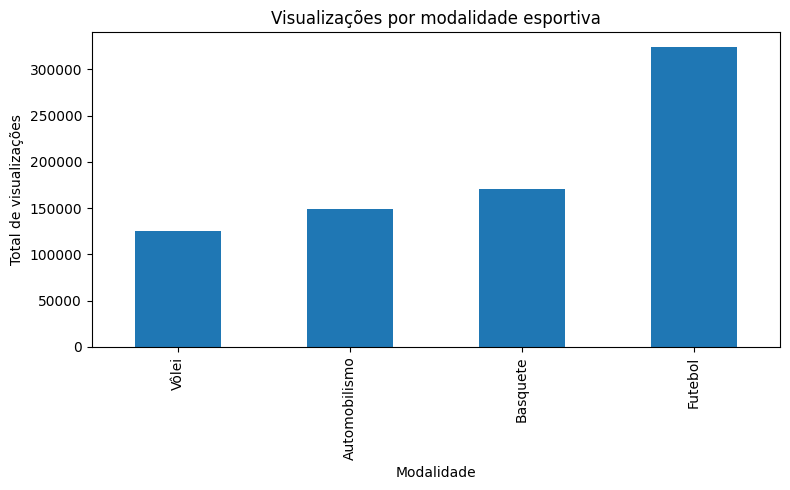

In [23]:

modalidades.sort_values().plot(kind="bar", figsize=(8, 5))
plt.title("Visualizações por modalidade esportiva")
plt.xlabel("Modalidade")
plt.ylabel("Total de visualizações")
plt.tight_layout()
plt.show()

4 - Comparar alcance e qualidade

In [20]:
print("Maior alcance:")
display(dados.sort_values("visualizacoes", ascending=False)[
    ["titulo", "visualizacoes", "taxa_engajamento_pct"]
].head(3))

print("Maior engajamento:")
display(dados.sort_values("taxa_engajamento_pct", ascending=False)[
    ["titulo", "visualizacoes", "taxa_engajamento_pct"]
].head(3))

Maior alcance:


,titulo,visualizacoes,taxa_engajamento_pct
16,Gol nos acréscimos domina as redes,75000,5.68
4,Os melhores lances do fim de semana,68000,5.25
0,Clássico nacional movimenta a rodada,52000,3.25


Maior engajamento:


,titulo,visualizacoes,taxa_engajamento_pct
22,Vitória no tie-break gera repercussão,27000,10.481481
18,Rali mais longo da partida em detalhes,24000,10.000000
14,Torcida transforma ginásio em caldeirão,19500,9.000000


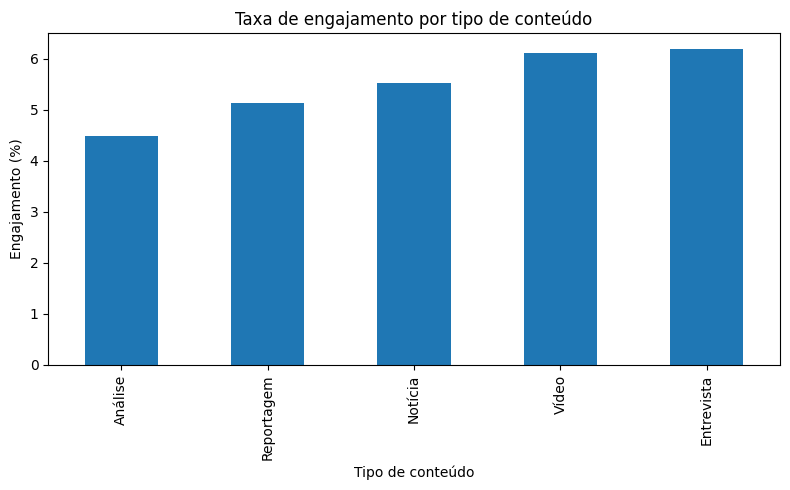

In [24]:

formatos["engajamento_pct"].sort_values().plot(kind="bar", figsize=(8, 5))
plt.title("Taxa de engajamento por tipo de conteúdo")
plt.xlabel("Tipo de conteúdo")
plt.ylabel("Engajamento (%)")
plt.tight_layout()
plt.show()

5 - Correlação entre variáveis

In [22]:
corr1 = dados[["tempo_medio_segundos", "compartilhamentos"]].corr().iloc[0, 1]
corr2 = dados[["visualizacoes", "novos_assinantes"]].corr().iloc[0, 1]

print("Tempo médio x compartilhamentos:", round(corr1, 3))
print("Visualizações x novos assinantes:", round(corr2, 3))

Tempo médio x compartilhamentos: 0.098
Visualizações x novos assinantes: 0.547


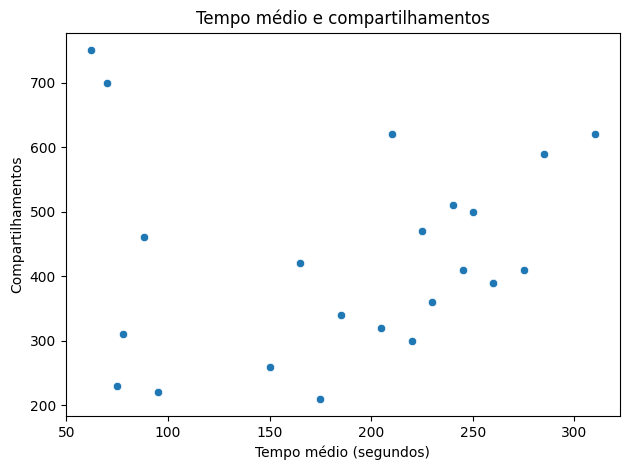

In [25]:

sns.scatterplot(data=dados, x="tempo_medio_segundos", y="compartilhamentos")
plt.title("Tempo médio e compartilhamentos")
plt.xlabel("Tempo médio (segundos)")
plt.ylabel("Compartilhamentos")
plt.tight_layout()
plt.show()

6 - Três insights editoriais

In [26]:

por_modalidade = dados.groupby("modalidade").agg(
    visualizacoes=("visualizacoes", "sum"),
    interacoes=("total_interacoes", "sum"),
    assinantes=("novos_assinantes", "sum")
)
por_modalidade["engajamento_pct"] = (
    por_modalidade["interacoes"] / por_modalidade["visualizacoes"] * 100
)
display(por_modalidade.round(2))


display(formatos.round(2))

,visualizacoes,interacoes,assinantes,engajamento_pct
modalidade,,,,
Automobilismo,149000,7120,793,4.78
Basquete,171000,8290,617,4.85
Futebol,324000,15240,975,4.70
Vôlei,125500,11615,692,9.25


,interacoes,visualizacoes,tempo_medio,assinantes,receita,cliques,engajamento_pct,taxa_conversao_pct,rpm
tipo_conteudo,,,,,,,,,
Análise,6055,135000,176.00,583,15400,12700,4.49,4.59,114.07
Entrevista,7070,114000,273.33,530,14100,11100,6.20,4.77,123.68
Notícia,12505,226000,78.00,671,18600,17700,5.53,3.79,82.30
Reportagem,7165,139500,237.00,683,19100,13950,5.14,4.90,136.92
Vídeo,9470,155000,251.25,610,16200,13800,6.11,4.42,104.52
